[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ChristofherdoVP/stokes-solar/blob/main/notebooks/04_mancha_sintetica.ipynb)

# Notebook 04 — Mapa sintético de uma mancha solar

Acompanha a Seção 5.3 do artigo. Gera a Figura 5 do artigo.

Em vez de dados reais, construímos uma mancha solar com campo conhecido em cada pixel, sintetizamos os perfis de
Stokes de Fe I 630,25 nm com a amostragem espectral do Hinode/SP (21,5 mÅ) e ruído de fótons, e aplicamos a
aproximação de campo fraco. Como o campo verdadeiro é conhecido, o erro do método pode ser medido pixel a pixel.

O modelo da mancha é deliberadamente simples, apenas para fins didáticos:
- umbra com campo quase vertical e intenso; penumbra com campo mais fraco e cada vez mais inclinado; azimute radial;
- fotosfera calma com alguns elementos de rede magnética, de algumas centenas de gauss e polaridades opostas;
- brilho do contínuo menor na umbra e na penumbra.

In [1]:
# Executa também no Google Colab: clona o repositório se necessário
import sys, os, subprocess
if 'google.colab' in sys.modules and not os.path.exists('stokes-solar'):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/ChristofherdoVP/stokes-solar.git'], check=True)
    os.chdir('stokes-solar/notebooks')

In [2]:
import sys; sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt
import stokespy as sp
from stokespy.estilo import setup, virgula, salvar, CORES, PAGINA
setup()
rng = np.random.default_rng(2026)

## 1. O modelo da mancha

In [3]:
N = 96                      # pixels por lado
pix = 0.3                   # segundos de arco por pixel (apenas para os eixos)
y, x = (np.mgrid[0:N, 0:N] - (N - 1)/2) * pix
r = np.hypot(x, y); Ru, Rp = 4.0, 10.0      # raios da umbra e da penumbra (")

B0 = 2800.0                                  # campo no centro da umbra (G)
B = np.where(r <= Rp, B0 * (1 - 0.72*(r/Rp)**2), 0.0)
gamma = np.where(r <= Rp, np.deg2rad(80) * (r/Rp)**1.3, 0.0)
chi = np.arctan2(y, x)

# rede magnética na fotosfera calma: elementos gaussianos verticais de polaridades opostas
rede_campo = np.zeros_like(r)
for _ in range(14):
    x0, y0 = rng.uniform(-13, 13, 2)
    if np.hypot(x0, y0) < Rp + 2: continue
    amp = rng.uniform(250, 700) * rng.choice([-1, 1])
    rede_campo += amp * np.exp(-((x - x0)**2 + (y - y0)**2) / (2 * 0.6**2))
fora = r > Rp
B = np.where(fora, np.abs(rede_campo), B)
gamma = np.where(fora, np.where(rede_campo >= 0, 0.0, np.pi), gamma)

# brilho do contínuo: umbra 0,25, penumbra 0,75, fotosfera calma 1 (transições suaves)
Ic = 1 - 0.125*(1 + np.tanh((Rp - r)/0.4)) - 0.25*(1 + np.tanh((Ru - r)/0.3))
BLOS_true = B * np.cos(gamma)
print(f'B máximo = {B.max():.0f} G; B_LOS de {BLOS_true.min():.0f} a {BLOS_true.max():.0f} G; I_c na umbra = {Ic[N//2, N//2]:.2f}')

B máximo = 2799 G; B_LOS de -535 a 2799 G; I_c na umbra = 0.25


## 2. Síntese dos perfis com amostragem do Hinode/SP e ruído

In [4]:
L = sp.LINHAS['Fe I 630,25 nm']; lam0, g = L['lam0'], L['g']
lam = lam0 + np.arange(-30, 31) * 0.0215                 # 61 pontos, passo de 21,5 mÅ
dlD = sp.doppler_width(lam0, 6000, 1.0)
sigma = 1e-3                                             # ruído em unidades do contínuo da fotosfera calma
cubo = np.empty((N, N, 4, lam.size))
for i in range(N):
    for j in range(N):
        S = sp.me_synthesis(lam, lam0, g, B[i, j], gamma[i, j], chi[i, j], vlos=0.0, dlD=dlD,
                            eta0=10.0, a=0.15, S0=0.3*Ic[i, j], S1=0.7*Ic[i, j])
        cubo[i, j] = S + rng.normal(0, sigma, S.shape)
print('cubo de Stokes:', cubo.shape, '(y, x, Stokes, λ)')

cubo de Stokes: (96, 96, 4, 61) (y, x, Stokes, λ)


## 3. Campo fraco pixel a pixel

In [5]:
BLOS_wfa = sp.wfa_blos(lam, cubo[:, :, 0], cubo[:, :, 3], lam0, g)
umbra, penumbra, calma = r <= Ru, (r > Ru) & (r <= Rp), r > Rp
rede = calma & (np.abs(BLOS_true) > 100)
for nome, m in [('umbra', umbra), ('penumbra', penumbra), ('rede magnética', rede)]:
    razao = np.median(BLOS_wfa[m] / BLOS_true[m])
    print(f'{nome:15s}: |B_LOS| verdadeiro {np.abs(BLOS_true[m]).min():5.0f}–{np.abs(BLOS_true[m]).max():5.0f} G;'
          f' razão mediana recuperado/verdadeiro = {razao:.2f}')
fraco = calma & (np.abs(BLOS_true) < 5)
print(f'ruído em B_LOS onde o campo é nulo: {BLOS_wfa[fraco].std():.1f} G')

umbra          : |B_LOS| verdadeiro  2262– 2799 G; razão mediana recuperado/verdadeiro = 0.09
penumbra       : |B_LOS| verdadeiro   137– 2249 G; razão mediana recuperado/verdadeiro = 0.98
rede magnética : |B_LOS| verdadeiro   101–  535 G; razão mediana recuperado/verdadeiro = 1.09
ruído em B_LOS onde o campo é nulo: 1.3 G


## 4. Figura 5 do artigo — campo verdadeiro, campo fraco e comparação

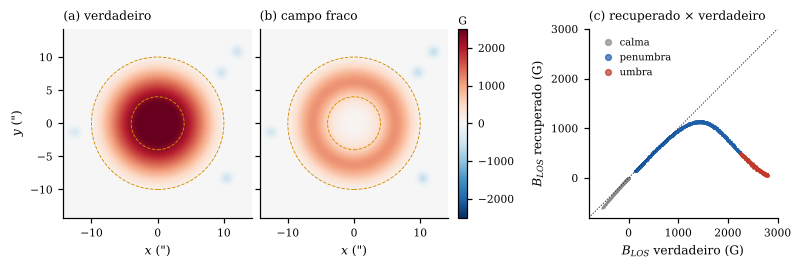

In [6]:
setup(base=8)
fig = plt.figure(figsize=(PAGINA, 2.45))
a1 = fig.add_axes([0.06, 0.17, 0.25, 0.70]); a2 = fig.add_axes([0.315, 0.17, 0.25, 0.70])
cax = fig.add_axes([0.575, 0.17, 0.012, 0.70]); a3 = fig.add_axes([0.745, 0.17, 0.245, 0.70])
ext = [x.min(), x.max(), y.min(), y.max()]; lim = 2500
for ax, mapa, tit in [(a1, BLOS_true, '(a) verdadeiro'), (a2, BLOS_wfa, '(b) campo fraco')]:
    im = ax.imshow(mapa, origin='lower', extent=ext, cmap='RdBu_r', vmin=-lim, vmax=lim)
    ax.set_title(tit, loc='left'); ax.set_xlabel('$x$ (")')
    for R in (Ru, Rp): ax.add_patch(plt.Circle((0, 0), R, fill=False, color=CORES['destaque'], lw=0.6, ls='--'))
a1.set_ylabel('$y$ (")'); a2.set_yticklabels([])
cb = fig.colorbar(im, cax=cax); cax.set_title('G', fontsize=7, pad=3)
for nome, m, cor in [('calma', calma, CORES['cinza']), ('penumbra', penumbra, CORES['Q']), ('umbra', umbra, CORES['V'])]:
    a3.plot(BLOS_true[m], BLOS_wfa[m], '.', ms=1.5, color=cor, label=nome, alpha=0.7)
a3.plot([-800, 3000], [-800, 3000], color=CORES['I'], lw=0.7, ls=':')
a3.set_xlim(-800, 3000); a3.set_ylim(-800, 3000)
a3.set_xlabel('$B_{LOS}$ verdadeiro (G)'); a3.set_ylabel('$B_{LOS}$ recuperado (G)'); a3.set_title('(c) recuperado × verdadeiro', loc='left')
a3.legend(frameon=False, markerscale=5, loc='upper left', fontsize=6.5, handletextpad=0.2)
a3.set_xticks([0, 1000, 2000, 3000]); a3.set_yticks([0, 1000, 2000, 3000])
salvar(fig, 'fig5_mancha')
setup()

## Exercícios

1. Aumente o ruído para $3\times10^{-3}$ e veja como muda o ruído do mapa de $B_{LOS}$ na fotosfera calma.
2. Inclua o escoamento de Evershed: uma velocidade radial na penumbra, observada fora do centro do disco.
3. Substitua o campo fraco por um ajuste de Milne-Eddington completo (por exemplo, com `scipy.optimize.least_squares`) e compare na umbra.
4. **Para ir além:** repita a análise com um mapa real do Hinode/SP, disponível no arquivo público da missão.